In [1]:

#script modified from Barnes EA et. al (2022) doi: 10.1175/AIES-D-22-0001.1 and Chen C et al (2019) doi: 10.48550/arXiv.1806.10574 to include channel-specific prototypes


from preprocess_data import Custom_Dataset, ChannelMNISTDataset
from torch.utils.data import DataLoader
import torch
from push_prototypes import push
import h5py
from receptive_field import compute_rf, output_to_input
import matplotlib.pyplot as plt
import numpy as np
import matplotlib.patches as patches
import cartopy.crs as ccrs
import cartopy.mpl.ticker as cticker
from cartopy.util import add_cyclic_point
from sklearn.tree import DecisionTreeClassifier
from sklearn import metrics
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import torch.optim.lr_scheduler as lr_scheduler
from torchgeo_euro import EuroSAT, ScaleAndNormalize
from torchvision.transforms import v2 as transforms
import torch.nn as nn 
from receptive_field import compute_rf, output_to_input
import pickle
import captum


if torch.cuda.is_available():
    torch.set_default_device('cuda')
    torch.set_default_tensor_type(torch.cuda.FloatTensor)
    device = torch.device('cuda')
    print("GPU is set as the default device.")
else:
    print("CUDA is not available. CPU will be used as the default device.")
    device = 'cpu'


#set nc=True to run Prototype Network (No Channel-Specific Prototypes)
nc = True 
if nc == True:
    from model_nc_lrp import BaseConvModel, ProtoModel, FinalLayer, WholeModel, exp_var_dict
else:
    from model import BaseConvModel, ProtoModel, FinalLayer, WholeModel, exp_var_dict

#Model save info
model_save = False
#if model_save == True:
    #pick_name = ''
    #model_name = ''
cross_loss = nn.CrossEntropyLoss()


#Training Parameters
base_epochs = 25
train_epochs = 50
exp_dataset = exp_var_dict['exp_dataset']

# Determines at which epoch to run Stage 2
def push_epoch(epoch, flag, delay_push_epoch = 10):
    if flag: #Project Stage 2 every training cycle
        return (epoch % 2 == 0)
    else: #Project Stage 2 as per delay_push_epoch parameter
        return (epoch % delay_push_epoch == 0)


#Load in dataset
if exp_dataset=='mjo':
    lead_time = 0
    #file_name = "/oscar/home/anaray34/data/anaray34/data/processed_mjo_data/processed_mjo_noise.hdf5"
    file_name = "/oscar/home/anaray34/data/anaray34/data/processed_mjo_data/processed_mjo.hdf5"

    train_data = Custom_Dataset(hdf5_data_file=file_name, im_name='train_images',label_name='train_labels', exp_dataset=exp_dataset)
    val_data = Custom_Dataset(hdf5_data_file=file_name, im_name='val_images',label_name='val_labels', exp_dataset=exp_dataset)
    test_data = Custom_Dataset(hdf5_data_file=file_name, im_name='test_images',label_name='test_labels', exp_dataset=exp_dataset)

    with h5py.File(file_name,'r') as f:
        all_images = f['train_images'][:]
        all_labels = f['train_labels'][:]
        all_times = f['train_time'][:]
        test_images = f['test_images'][:]
        test_labels = f['test_labels'][:]

    train_dataloader = DataLoader(train_data, batch_size = exp_var_dict['batch_size'])
    val_dataloader = DataLoader(val_data)
    test_dataloader = DataLoader(test_data, shuffle=False)
    push_dataloader = DataLoader(train_data, batch_size = len(all_images), shuffle=False)

elif exp_dataset == 'mnist':
    train_data = ChannelMNISTDataset(hdf5_data_file='/oscar/home/anaray34/data/anaray34/data/syntheticMNIST/synthetic_data_channelmnist.hdf5', im_name='train_images',label_name='train_labels')
    val_data = ChannelMNISTDataset(hdf5_data_file='/oscar/home/anaray34/data/anaray34/data/syntheticMNIST/synthetic_data_channelmnist.hdf5', im_name='val_images',label_name='val_labels')
    test_data = ChannelMNISTDataset(hdf5_data_file='/oscar/home/anaray34/data/anaray34/data/syntheticMNIST/synthetic_data_channelmnist.hdf5', im_name='test_images',label_name='test_labels')

    with h5py.File("/oscar/home/anaray34/data/anaray34/data/syntheticMNIST/synthetic_data_channelmnist.hdf5",'r') as f:
        all_images = f['train_images'][:]
        all_labels = f['train_labels'][:]
        test_images = f['test_images'][:]
        
    train_dataloader = DataLoader(train_data, batch_size = exp_var_dict['batch_size'])
    val_dataloader = DataLoader(val_data)
    test_dataloader = DataLoader(test_data)
    push_dataloader = DataLoader(train_data, batch_size = len(all_images), shuffle=False)


elif exp_dataset == 'euro_rs':
    root='/oscar/home/anaray34/data/anaray34/data/EuroSAT/eurosat_data_train'
    min=[816.,   0.,   0.,   0., 174., 153., 128.,   0.,  40.,   1.,   5.,   1., 91.]
    max=[17720., 28000., 28000., 28000., 23381., 27791., 28001., 28002., 15384.,183., 24704., 22210., 28000.]

    mean = [1354.4054, 1118.2439, 1042.9299,  947.6262, 1199.4728, 1999.7909, 2369.2229, 2296.8262,  732.0834,   12.1133, 1819.0103, 1118.9240, 2594.1406]
    std = [ 245.7176,  333.0078,  395.0925,  593.7505,  566.4170,  861.1840, 1086.6315, 1117.9817,  404.9198,    4.7758, 1002.5877,  761.3033, 1231.5858]
    
    scale_and_normalize_transform = ScaleAndNormalize(mean, std)

    train_dataset = EuroSAT(root, split='train', download=False, transforms=scale_and_normalize_transform)
    val_dataset = EuroSAT(root, split='val', download=False, transforms=scale_and_normalize_transform)
    test_dataset = EuroSAT(root, split='test', download=False, transforms=scale_and_normalize_transform)
    generator = torch.Generator(device)

    train_dataloader = DataLoader(train_dataset, batch_size = exp_var_dict['batch_size'], generator=generator, shuffle=True)
    val_dataloader = DataLoader(val_dataset, batch_size = exp_var_dict['batch_size'], generator=generator)
    test_dataloader = DataLoader(test_dataset, generator=generator)
    push_dataloader = DataLoader(train_dataset, batch_size = len(train_dataset), shuffle=False, generator=generator)



/users/anaray34/.local/lib/python3.11/site-packages/torchvision/io/image.py:13: UserWarning: Failed to load image Python extension: 'Could not load this library: /oscar/home/anaray34/.local/lib/python3.11/site-packages/torchvision/image.so'If you don't plan on using image functionality from `torchvision.io`, you can ignore this warning. Otherwise, there might be something wrong with your environment. Did you have `libjpeg` or `libpng` installed before building `torchvision` from source?
  warn(
/users/anaray34/.local/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


CUDA is not available. CPU will be used as the default device.
Input Shape: torch.Size([11315, 3, 16, 131])
Input Shape: torch.Size([1095, 3, 16, 131])
Input Shape: torch.Size([1095, 3, 16, 131])


In [2]:
############## Train Standard Neural Network without Prototypes ##############################
base = BaseConvModel(exp_dataset, CNN_only = True)
base_optimizer = torch.optim.Adam([{'params':base.parameters()}], lr=0.001)

optimizer = base_optimizer
for epoch in range(base_epochs):
    epoch_cross_entropy = 0
    tn_examples = 0
    tn_correct = 0
    for inputs, labels in train_dataloader:
        inputs = torch.nan_to_num(inputs)
        base.train()
        with torch.enable_grad():
            output = base(inputs)
            cross_entropy = cross_loss(output, labels.to(torch.long))
            output = torch.nn.functional.softmax(output)

            predicted = torch.max(output.data, 1)
            tn_examples += labels.size(0)
            tn_correct += torch.eq(predicted[1], labels).sum().item()

        loss = cross_entropy 
        epoch_cross_entropy += loss.item()
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

    val_epoch_cross_entropy = 0
    n_examples = 0
    n_correct = 0
    for inputs, labels in val_dataloader:
        inputs = torch.nan_to_num(inputs)
        base.eval()
        with torch.no_grad():
            output = base(inputs)
            cross_entropy = cross_loss(output, labels.to(torch.long))
            output = torch.nn.functional.softmax(output)

            predicted = torch.max(output.data, 1)
            n_examples += labels.size(0)
            n_correct += torch.eq(predicted[1], labels).sum().item()
            
            val_epoch_cross_entropy+= cross_entropy.item()
    print('Epoch '+str(epoch)+' Train Accuracy: '+str(tn_correct/tn_examples))
    print('Epoch '+str(epoch)+' Val Accuracy: '+str(n_correct/n_examples))

true_label = []
pred_label = []
n_examples = 0
n_correct = 0
n_correct_1 = 0
for inputs, labels in test_dataloader:
    inputs = torch.nan_to_num(inputs)
    base.eval()
    with torch.no_grad():
        output = base(inputs)
        cross_entropy = cross_loss(output, labels.to(torch.long))
        output = torch.nn.functional.softmax(output)

        predicted = torch.max(output.data, 1)
        n_examples += labels.size(0)
        n_correct += torch.eq(predicted[1], labels).sum().item()
        n_correct_1 += (abs(predicted[1]-labels) < 2).sum().item()
        true_label.append(int(labels.cpu().item()))
        pred_label.append(predicted[1].cpu().item())
print('Test Accuracy: '+str(n_correct/n_examples))
print('+1 Test Accuracy: '+str(n_correct_1/n_examples))



/tmp/ipykernel_1599171/2931203209.py:16: UserWarning: Implicit dimension choice for softmax has been deprecated. Change the call to include dim=X as an argument.
  output = torch.nn.functional.softmax(output)
/tmp/ipykernel_1599171/2931203209.py:37: UserWarning: Implicit dimension choice for softmax has been deprecated. Change the call to include dim=X as an argument.
  output = torch.nn.functional.softmax(output)


Epoch 0 Train Accuracy: 0.47962881131241714
Epoch 0 Val Accuracy: 0.5059360730593607
Epoch 1 Train Accuracy: 0.5664162615996465
Epoch 1 Val Accuracy: 0.5333333333333333
Epoch 2 Train Accuracy: 0.5829429960229784
Epoch 2 Val Accuracy: 0.5488584474885845
Epoch 3 Train Accuracy: 0.6072470172337605
Epoch 3 Val Accuracy: 0.5515981735159817
Epoch 4 Train Accuracy: 0.6211224038886434
Epoch 4 Val Accuracy: 0.5652968036529681
Epoch 5 Train Accuracy: 0.6311091471498012
Epoch 5 Val Accuracy: 0.5515981735159817
Epoch 6 Train Accuracy: 0.6532920901458241
Epoch 6 Val Accuracy: 0.5716894977168949
Epoch 7 Train Accuracy: 0.6577993813521874
Epoch 7 Val Accuracy: 0.5662100456621004
Epoch 8 Train Accuracy: 0.6694653115333628
Epoch 8 Val Accuracy: 0.5726027397260274
Epoch 9 Train Accuracy: 0.6800707026071586
Epoch 9 Val Accuracy: 0.5570776255707762
Epoch 10 Train Accuracy: 0.6982766239505082
Epoch 10 Val Accuracy: 0.54337899543379
Epoch 11 Train Accuracy: 0.7044631020768891
Epoch 11 Val Accuracy: 0.558904

/tmp/ipykernel_1599171/2931203209.py:58: UserWarning: Implicit dimension choice for softmax has been deprecated. Change the call to include dim=X as an argument.
  output = torch.nn.functional.softmax(output)


Test Accuracy: 0.491324200913242
+1 Test Accuracy: 0.776255707762557


In [ ]:
from captum.attr import LRP
from captum.attr import visualization as viz
from captum.attr._utils.lrp_rules import EpsilonRule, GammaRule, Alpha1_Beta0_Rule


/users/anaray34/.conda/envs/mjo_env/lib/python3.11/site-packages/captum/attr/_core/lrp.py:207: UserWarning: Input Tensor 0 did not already require gradients, required_grads has been set automatically.
  gradient_mask = apply_gradient_requirements(input_tuple)


/users/anaray34/.conda/envs/mjo_env/lib/python3.11/site-packages/captum/attr/_core/lrp.py:207: UserWarning: Input Tensor 0 did not already require gradients, required_grads has been set automatically.
  gradient_mask = apply_gradient_requirements(input_tuple)


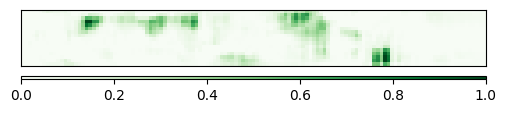

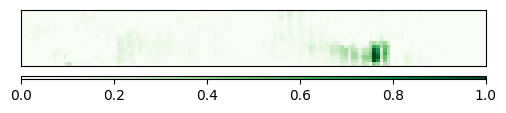

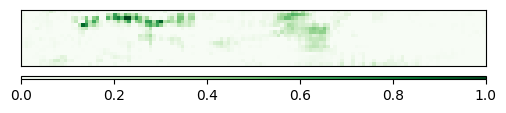

In [ ]:
for batch_idx, batch_data in enumerate(test_dataloader):
  if batch_idx == 12:
    break

base.eval()


for module in base.modules():
    module.rule = EpsilonRule(epsilon=0)


lrp = LRP(base)

attributions_lrp = lrp.attribute(
    inputs=batch_data[0],
    target=int(batch_data[1].item())
)




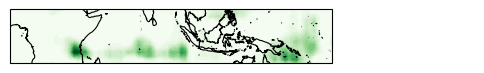

In [ ]:
lats = np.linspace(-15, 15, 16)
lons = np.arange(0, 262, 2)

attr = attributions_lrp[0, 0].detach().cpu().numpy()

# Positive LRP
attr = np.maximum(attr, 0)
attr = attr / (attr.max() + 1e-8)

fig, ax = plt.subplots(
    1, 1,
    subplot_kw={
        'projection': ccrs.PlateCarree(central_longitude=0)
    },
    figsize=(6, 9)
)

ax.set_xlim(0, 260)
ax.set_ylim(-15, 15)

contour = ax.contourf(
    lons,
    lats,
    attr,
    levels=20,
    cmap='Greens',
    vmin=0,
    vmax=1,
)

ax.coastlines(
    color='black',
    linewidth=0.8,
    zorder=10
)
#plt.savefig('mjo_12_lrp_channel0.pdf', format='pdf', bbox_inches='tight')
plt.show()